# Real hardware

Every job in `results/` that ran on a real quantum device, whatever the device
or provider: what was sent, the noise measured in the job, every board, and how
often the detector found the win. Each job holds 18 calibration circuits (8
readout circuits, a board with a known winner on each of the 8 lines, and 2
boards without one) and the labeled boards. Everything below
is read from the saved records, so re-running this notebook is free and needs
no account. Until a hardware job has been saved, the notebook says so and shows
nothing else; simulated runs are in `02_noise`.

**Sending a job** (optional, IBM devices only so far): put `QISKIT_IBM_TOKEN=...`
in the repo's `.env` (see `.env.example`), set `SUBMIT_TO` and
`RUN_HARDWARE = True`, run the notebook once, then set it back to False. The
same batch can be sent from a terminal with
`python scripts/collect.py --backend ibm_kingston --n 30 --seed 4903 --shots auto --tag kingston-1`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from qttt.analysis import jobs, rescore, summarize, wrong_winners
from qttt.backends import get_backend
from qttt.experiments import choose_shots, collect, sample_boards
from qttt.noise import CALIBRATION_CIRCUITS
from qttt.results import RunStore

STORE = RunStore("../results")
HARDWARE_ONLY = True  # False also shows simulated jobs saved in STORE (the tests use this)

# Sending a new job (optional)
RUN_HARDWARE = False  # True submits one job to SUBMIT_TO (uses your plan's time)
SUBMIT_TO = "ibm_kingston"
N_BOARDS = 30  # balanced over label, winning line, last mover and turn
SEED = 4903
SHOTS = "auto"  # a short calibration job first picks the shots for at most 1% misses, up to MAX_SHOTS
MAX_SHOTS = 4096
TAG = "kingston-1"

## Send a job (only when `RUN_HARDWARE = True`)

In [2]:
if RUN_HARDWARE:
    boards = sample_boards(N_BOARDS, seed=SEED)
    device = get_backend(SUBMIT_TO, seed=SEED, transpile_seeds=5)
    shots = SHOTS
    if shots == "auto":
        shots, _ = choose_shots(device, max_shots=MAX_SHOTS, store=STORE, tag=TAG)
        print(f"A calibration job on {SUBMIT_TO} chose {shots} shots per board.")
    print(f"Submitting {len(boards)} boards + {CALIBRATION_CIRCUITS} calibration circuits to {SUBMIT_TO}"
          f" ({shots} shots each)...")
    collect(boards, device, shots=shots, store=STORE, tag=TAG)
    print("Done; saved to", STORE.runs_file)

## Saved jobs

One line per job, oldest first, with the device's own calibration date, the
compiled circuit and the error-suppression options it ran with.

Every verdict below is recomputed from the job's saved counts with the
current calibration rule (`qttt.analysis.rescore`): the profile is fitted again
from the calibration counts saved with the job, so a job collected under an
older rule is scored the same way as a new one. The verdicts decided at run
time stay in the saved records.

In [3]:
saved = [rescore(job) for job in jobs(STORE, hardware_only=HARDWARE_ONLY)]
if not saved:
    print(f"No hardware results saved yet in {STORE.root}.")
for job in saved:
    b, m = job.backend, job.first["metrics"]
    print(f"{job.label}: tag {job.first['tag']}, job {job.first['job_id']}, {len(job.detections)} boards,"
          f" {job.first['shots']} shots, device calibration data from {b['calibration_date'] or 'unpublished'}")
    print(f"    circuit: {m['two_qubit_gates']} two-qubit gates, depth {m['depth']}, line qubits {m['line_qubits']},"
          f" ancilla {'yes' if m.get('ancilla') else 'no'};"
          f" Sampler options: {b['options'].get('sampler_options') or 'none'}")
    changed = sum(d["lines"] != d["lines_at_run"] for d in job.detections)
    if changed:
        print(f"    re-scored with the current calibration rule: {changed} board(s) differ from the verdict at run time")

ibm ibm_marrakesh 2026-11-15: tag marrakesh-batch-1, job dbsumtnasvbs73b945k0, 3 boards, 1024 shots, device calibration data from 2026-11-13T12:22:56-05:00
    circuit: 431 two-qubit gates, depth 1079, line qubits [53, 54, 39], ancilla yes; Sampler options: none


## Noise measured in each job

The 8 readout circuits give the readout matrix A (how often each prepared line
index is read as each other one). The eight known-winner boards (one per
line) give ε, the share of shots gate noise scatters, and how much signal each
bit of the line index keeps when it is 1. The two no-win boards show how high
losing lines get. Together they set each line's cutoff.

ibm ibm_marrakesh 2026-11-15: ε = 0.904; correct readout per line index [0.978, 0.976, 0.982, 0.973, 0.975, 0.963, 0.969, 0.96]
    cutoffs at 1024 shots: [171, 167, 169, 150, 164, 154, 167, 152]; shots for ≤1% misses with this noise: more than 16384


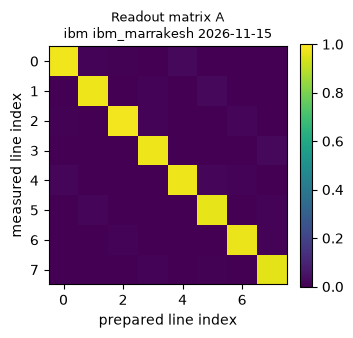

In [4]:
if saved:
    fig, axes = plt.subplots(1, len(saved), figsize=(3.4 * len(saved), 3.2), squeeze=False)
    for ax, job in zip(axes[0], saved, strict=True):
        profile = job.measured_profile
        needed = profile.shots_needed(0.01, job.first["budget"])
        print(f"{job.label}: ε = {profile.epsilon:.3f};"
              f" correct readout per line index {[round(profile.readout[i][i], 3) for i in range(8)]}")
        print(f"    cutoffs at {job.first['shots']} shots: {job.first['cutoffs']};"
              f" shots for ≤1% misses with this noise: {needed or 'more than 16384'}")
        image = ax.imshow(profile.readout, cmap="viridis", vmin=0, vmax=1)
        ax.set_xlabel("prepared line index")
        ax.set_ylabel("measured line index")
        ax.set_title(f"Readout matrix A\n{job.label}", fontsize=9)
    fig.colorbar(image, ax=axes[0].tolist(), fraction=0.046)
    plt.show()

## Every board

**Reading the bar charts:** each bar is the fraction of shots measured on a
line index. Green: the board's real winning lines. Gray: losing lines.
Orange: a losing line that reached its cutoff, so it was flagged and then
rejected by the classical check. The black tick on each bar is that line's
cutoff (from the noise profile measured in the job), and the dotted line is
1/8, an even spread over all 8 lines. Line numbers, as in `01_how_it_works`:
0 top row, 1 middle row, 2 bottom row, 3 left column, 4 middle column,
5 right column, 6 diagonal from top-left, 7 diagonal from top-right.


ibm ibm_marrakesh 2026-11-15
  #  board                                                      confirmed  rejected on winning lines  verdict
  1  no winner (X just moved, turn 5)                                  []        []                -  correct
  2  X wins the top row (turn 5)                                       []       [2]            16.2%  MISSED
  3  X wins the middle row and left column (turn 9)                    []       [0]            29.4%  MISSED


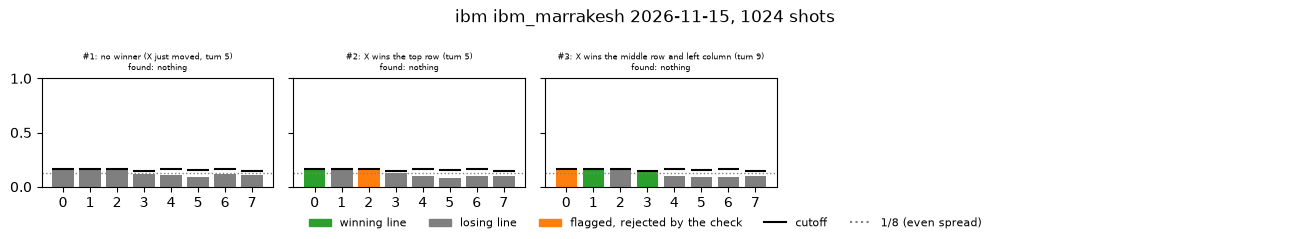

In [5]:
LEGEND = [Patch(color="tab:green", label="winning line"), Patch(color="tab:gray", label="losing line"),
          Patch(color="tab:orange", label="flagged, rejected by the check"),
          Line2D([], [], color="black", linewidth=1.5, label="cutoff"),
          Line2D([], [], color="gray", linestyle=":", label="1/8 (even spread)")]


# Short line names for tables and titles (line numbers as in 01_how_it_works).
LINES = ("top row", "middle row", "bottom row", "left column", "middle column", "right column",
         "diagonal from top-left", "diagonal from top-right")


def describe(r):
    """A board in words: who just moved, on which turn, and its real winning lines."""
    turn = r.get("turn") or 9 - r["board"].count(" ")
    if not r["true_lines"]:
        return f"no winner ({r['player']} just moved, turn {turn})"
    return f"{r['player']} wins the {' and '.join(LINES[i] for i in r['true_lines'])} (turn {turn})"


def verdict(r):
    true, found = set(r["true_lines"]), set(r["lines"])
    if not true:
        return "correct" if not found else "WRONG"
    return "correct" if found == true else "partly missed" if found else "MISSED"


for job in saved:
    print(f"\n{job.label}")
    print(f"{'#':>3}  {'board':58} {'confirmed':>9} {'rejected':>9} {'on winning lines':>16}  verdict")
    for number, r in enumerate(job.detections, start=1):
        true = r["true_lines"]
        share = f"{sum(r['counts'][i] for i in true) / r['shots']:.1%}" if true else "-"
        print(f"{number:>3}  {describe(r):58} {str(r['lines']):>9} {str(r['rejected']):>9} {share:>16}  {verdict(r)}")

    cols = 5
    rows = -(-len(job.detections) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.3 * rows), sharey=True, squeeze=False)
    for number, (ax, r) in enumerate(zip(axes.flat, job.detections), start=1):
        true = set(r["true_lines"])
        colors = ["tab:green" if i in true else "tab:orange" if i in r["rejected"] else "tab:gray" for i in range(8)]
        ax.bar(range(8), [c / r["shots"] for c in r["counts"]], color=colors)
        ax.hlines([k / r["shots"] for k in r["cutoffs"]], [i - 0.4 for i in range(8)], [i + 0.4 for i in range(8)],
                  color="black", linewidth=1.5)
        ax.axhline(1 / 8, color="gray", linestyle=":", linewidth=1)
        found = " and ".join(LINES[i] for i in r["lines"]) or "nothing"
        ax.set_title(f"#{number}: {describe(r)}\nfound: {found}", fontsize=6, wrap=True)
        ax.set_xticks(range(8))
        ax.set_ylim(0, 1)
    for ax in axes.flat[len(job.detections):]:
        ax.axis("off")
    fig.suptitle(f"{job.label}, {job.first['shots']} shots")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.legend(handles=LEGEND, loc="lower center", ncol=5, fontsize=8, frameon=False)
    plt.show()

## Summary

A missed win is a board with a winner where no line reached its cutoff. A
false flag is a losing line that reached its cutoff; the classical check
rejects it, so it costs one extra check but never produces a wrong winner. The
interval is a 95% Wilson interval for the share of wins found: with few boards
it is wide, which is the honest size of what a small batch can show.

The budget allows about 0.2 false flags per board. If no-win boards get clearly
more, the noise is not spreading shots evenly over the losing lines as the model
assumes: some lines pick up extra shots even on boards without a winner.

Checks per board counts the classical line checks; checking every line would be
8. That is not a speedup: every shot of the circuit evaluates the oracle on all
8 lines, and each board takes 1024 shots.

In [6]:
for job in saved:
    print(f"\n{job.label}")
    print(f"{'label':11} {'boards':>6} {'win found':>10} {'95% interval':>14} {'all lines':>10}"
          f" {'false flags':>11} {'checks/board':>12}")
    for row in summarize(job.detections):
        win = row.label != "no_win"
        low, high = row.found_interval
        found = f"{row.wins_found}/{row.boards}" if win else "-"
        interval = f"{low:.0%}-{high:.0%}" if win else "-"
        every = f"{row.all_lines_found}/{row.boards}" if win else "-"
        print(f"{row.label:11} {row.boards:>6} {found:>10} {interval:>14} {every:>10}"
              f" {row.false_flags:>11} {row.checks / row.boards:>12.2f}")
if saved:
    wrong = wrong_winners([d for job in saved for d in job.detections])
    assert not wrong, f"{len(wrong)} reported line(s) were not real wins"
    print("\nNo reported line was ever a wrong winner.")


ibm ibm_marrakesh 2026-11-15
label       boards  win found   95% interval  all lines false flags checks/board
no_win           1          -              -          -           0         0.00
single_win       1        0/1         0%-79%        0/1           1         1.00
double_win       1        0/1         0%-79%        0/1           1         1.00

No reported line was ever a wrong winner.


## Measured vs predicted

For each board with a winner: the share of shots on its winning line(s),
measured in the job, next to two predictions of the same simple model. One
uses the device's published calibration data, saved with the job when it was
submitted, for the same compiled circuit; it is left out for providers that
publish no gate errors. The other uses the noise profile measured in the job.

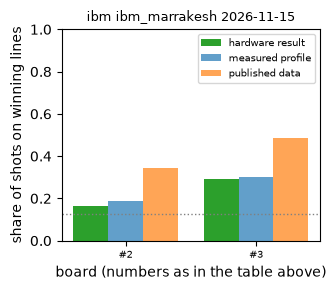

In [7]:
for job in saved:
    numbered = [(number, r) for number, r in enumerate(job.detections, start=1) if r["true_lines"]]
    wins = [r for _, r in numbered]
    if not wins:
        continue
    models = {"measured profile": job.measured_profile}
    if job.published_profile is not None:
        models["published data"] = job.published_profile
    width = 0.8 / (len(models) + 1)
    x = np.arange(len(wins))
    measured = [sum(r["counts"][i] for i in r["true_lines"]) / r["shots"] for r in wins]
    fig, ax = plt.subplots(figsize=(0.45 * len(wins) + 2.5, 3))
    ax.bar(x, measured, width, label="hardware result", color="tab:green")
    for k, (name, profile) in enumerate(models.items(), start=1):
        predicted = [sum(profile.predicted_for(r["true_lines"])[i] for i in r["true_lines"]) for r in wins]
        ax.bar(x + k * width, predicted, width, label=name, alpha=0.7)
    ax.axhline(1 / 8, color="gray", linestyle=":", linewidth=1)
    ax.set_xticks(x + width * len(models) / 2, [f"#{number}" for number, _ in numbered], fontsize=7)
    ax.set_xlabel("board (numbers as in the table above)")
    ax.set_ylabel("share of shots on winning lines")
    ax.set_ylim(0, 1)
    ax.set_title(job.label, fontsize=9)
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

Both predictions use the same model. The published one has a single ε for
every line; the profile measured in the job also gives each bit of the line
index its own signal factor, fitted on the eight known boards (each bit is 1 on
four of them). Gaps on particular boards show where the model is too simple.